<a href="https://colab.research.google.com/github/victorm0202/temas_selectos_CD_2026/blob/main/Notebooks/Gene_expression_clustering_working.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de datos de expresión genética: TCGA Pan-Cancer

El material de ésta sesión fue adaptado de:
<img src="https://drive.google.com/uc?export=view&id=1CMnXpAQlvpr6KI_0cSxEQnvuNfp7BnBo" alt="img1" width="80%">

Créditos:

- Nelly Sélem, Centro de Ciencias Matemáticas UNAM, México
- Victor Muñiz and Lilia Leticia Ramírez Ramírez CIMAT
- Juan Bizzotto, University of Buenos Aires

<img src="https://drive.google.com/uc?export=view&id=13LN4sSsNugFNzkk8DEFbkID_tuUA1btc" alt="img1" width="80%">



**Nota**: si el notebook se comparte directamente desde una carpeta en Google, crea una copia local en tu Google Drive para poder editarlo sin modificar el original.

Primero descargaremos los paquetes y datos necesarios.

1. Descarga todos los datos desde:
https://1drv.ms/u/c/d446169bfe3b3704/EdaggDgXpV9FvTPeaq6uK2IBvwob7NV2gRReI7jgVAlz8Q?e=qz5hNH

2. Descomprime el archivo localmente (deberías encontrar 4 archivos) y sube los 4 archivos manualmente.
3. Cuando todos los archivos estén disponibles, ejecuta la siguiente celda.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage

print("Setup complete. All required packages have been loaded.")

# Configuración general de las gráficas
#plt.rcParams["figure.figsize"] = (14, 7)

Setup complete. All required packages have been loaded.


## Para utilizar los datos compartidos de esta carpeta:

Ve a la carpeta compartida `metagenomics`(solo con cuenta de CIMAT): https://drive.google.com/drive/folders/1LE7qMphzfrUVUlMf6YQNGpJHd-JUm9yf?usp=drive_link

Selecciona Organizar → Añadir acceso directo.

<img src="https://drive.google.com/uc?export=view&id=14UNjWLkh_HR75FFTDEIB4ZyomN3eTyr9" alt="img1" width="80%">

Ve a Todas las ubicaciones.
Selecciona Mi unidad y luego Añadir.

<img src="https://drive.google.com/uc?export=view&id=1_oB11wBHkGzfHoq0KgCjufYEno9AU4JG" alt="img2" width="40%">

Monta tu unidad de Google Drive:

In [3]:
from google.colab import drive
import os
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


Cambia el directorio de trabajo.

En tu caso: $\verb|/content/drive/My Drive/metagenomics/|$

In [4]:
os.chdir('/content/drive/My Drive/Cursos/optativas_general/notebooks2026/metagenomics/')
!ls

data


# 1. Introducción
Esta sección proporciona un conjunto de datos adicional para practicar métodos de agrupamiento. Los datos ómicos de cáncer son adecuados para este ejercicio: proyectos como **The Cancer Genome Atlas (TCGA)** han generado datos de alta dimensionalidad de miles de tumores y numerosos tipos de cáncer ([Weinstein et al., 2013](https://www.nature.com/articles/ng.2764)). La elevada proporción de variables respecto al número de muestras hace que el aprendizaje automático (ML) y la inteligencia artificial (IA) sean herramientas esenciales para su análisis. Estos enfoques computacionales se utilizan con frecuencia para identificar patrones de relevancia biológica en la investigación del cáncer ([Hutter, 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X)). En particular, el agrupamiento es una herramienta exploratoria que permite identificar nuevos subgrupos de pacientes según sus perfiles moleculares, que pueden no corresponder a las clasificaciones tradicionales de las enfermedades.

![fig](https://www.cell.com/cms/10.1016/j.cell.2018.03.042/asset/97589225-3dd8-4601-862b-8915c45e6c5c/main.assets/gr1_lrg.jpg)
*Infografía que resume la magnitud del trabajo y los resultados de The Cancer Genome Atlas (TCGA) ([Hutter, 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X)).*

Este notebook presenta un **análisis exploratorio de un conjunto de datos pancáncer de The Cancer Genome Atlas (TCGA)**. El objetivo principal es aplicar técnicas de aprendizaje no supervisado, en particular agrupamiento y reducción de dimensionalidad, para identificar patrones en datos moleculares de alta dimensionalidad (transcriptómica y proteómica). Exploraremos cómo se relacionan estos patrones con anotaciones clínicas, como el tipo de enfermedad primaria y el origen de la muestra.

El conjunto de datos contiene información molecular y clínica de una amplia cohorte de pacientes con cáncer. Cada observación (fila) de la matriz molecular corresponde a una muestra de tejido de un paciente. Las muestras incluyen tumores primarios (en el lugar de origen), tejido sólido normal (tejido adyacente no canceroso), cánceres primarios de origen sanguíneo y lesiones metastásicas. Cada variable (columna) cuantifica un atributo molecular: según el conjunto de datos, puede ser la expresión de un gen o la abundancia de una proteína. La matriz se complementa con archivos de anotación que proporcionan información clínica de cada muestra, especialmente la enfermedad primaria (el tejido de origen del tumor) y el tipo de muestra. Para explorar estos datos y descargar características adicionales, se recomiendan varios recursos públicos. El navegador UCSC Xena ([https://xenabrowser.net/](https://xenabrowser.net/)) permite visualizar interactivamente los datos de TCGA. El portal GDC ([https://portal.gdc.cancer.gov/](https://portal.gdc.cancer.gov/)) es el repositorio principal para identificar y descargar los archivos disponibles, tanto originales como procesados.


# **2. Análisis de expresión génica (transcriptómica)**
En esta sección analizaremos el conjunto pancáncer de expresión génica. El archivo `README.md` del [repositorio](https://github.com/jbzt/cancer_data_for_cluster_and_classification) proporciona información esencial sobre el estudio.

## **2.1. Antecedentes: el conjunto transcriptómico pancáncer de TCGA**
Analizaremos un conjunto amplio de expresión génica procedente de la iniciativa **Pan-Cancer Atlas de The Cancer Genome Atlas (TCGA)**. Este proyecto caracterizó sistemáticamente más de 20 000 muestras de cáncer primario y muestras normales emparejadas, correspondientes a 33 tipos de cáncer ([Weinstein et al., 2013](https://doi.org/10.1038/ng.2764)). Su objetivo fue crear un atlas completo de las alteraciones moleculares —genómicas, epigenómicas, transcriptómicas y proteómicas— que impulsan distintos cánceres, e identificar semejanzas y diferencias entre linajes tumorales.

![Figura 1. Flujo conceptual del proyecto Pan-Cancer Atlas: integración de datos multiómicos de miles de muestras de pacientes y decenas de tipos de cáncer para identificar patrones moleculares comunes y distintos.](https://media.springernature.com/lw685/springer-static/image/art%3A10.1186%2Fs12967-023-03907-z/MediaObjects/12967_2023_3907_Fig1_HTML.png)

*Figura 1. Flujo conceptual del proyecto Pan-Cancer Atlas, que ilustra la integración de datos multiómicos para identificar patrones moleculares. Fuente: National Cancer Institute.*

Los datos transcriptómicos utilizados se generaron mediante **secuenciación de ARN (RNA-Seq)**, una tecnología de alto rendimiento que cuantifica la abundancia de ARN mensajero (ARNm) en una muestra biológica. Esto ofrece una instantánea de los genes activos en un momento determinado. En TCGA, RNA-Seq se realizó principalmente en muestras de **tumores sólidos primarios**. En muchos casos también se recogieron muestras emparejadas de **tejido sólido normal** del mismo paciente, como referencia para identificar cambios de expresión específicos del cáncer. En cánceres sanguíneos, como la leucemia mieloide aguda (LAML), las muestras procedían de sangre periférica.

**Normalización de los datos:** los conteos originales de lecturas de RNA-Seq requieren un procesamiento computacional considerable antes del análisis. Los datos de los archivos de «nivel 3» de TCGA, utilizados habitualmente para este tipo de análisis, ya han pasado por un flujo de procesamiento estandarizado. Este suele incluir alineamiento a un genoma de referencia y normalización para corregir variaciones técnicas, como diferencias de profundidad de secuenciación entre muestras. Entre los métodos habituales se encuentran FPKM (fragmentos por kilobase de transcrito por millón de lecturas mapeadas) y TPM (transcritos por millón), que permiten comparar niveles de expresión entre muestras y genes ([Zhao et al., 2021](https://doi.org/10.1016/j.csbj.2021.09.006)). El conjunto que utilizamos ya está preprocesado, por lo que podemos comenzar directamente el análisis exploratorio.

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Analiza brevemente el conjunto de datos y el problema que aborda. Menciona al menos **2 características** clave al trabajar con estos datos moleculares de alta dimensionalidad.
>
> *⏱️ Tiempo estimado: 10 minutos*

## 2.2. Carga de datos y análisis inicial
Carga los datos pancáncer de expresión génica.

In [5]:
!pip install pyreadr
import pyreadr   # pip install pyreadr: necesario para leer archivos .RDS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 13.6 MB/s eta 0:00:00


In [ ]:
local_path = "data/pan_cancer_dataset.RDS"
#local_path = "../../data/metagenomics/pan_cancer_dataset.RDS"
result = pyreadr.read_r(local_path)
# pyreadr devuelve un OrderedDict; tomar la primera (y única) tabla
df = list(result.values())[0]

In [ ]:
df

,gene,TCGA-S9-A7J2-01,TCGA-G3-A3CH-11,TCGA-EK-A2RE-01,TCGA-44-6778-01,TCGA-VM-A8C8-01,TCGA-AB-2863-03,TCGA-C8-A1HL-01,TCGA-EE-A17X-06,TCGA-YB-A89D-11,...,TCGA-DD-A4NR-01,TCGA-DJ-A2QC-01,TCGA-A8-A09K-01,TCGA-61-1907-01,TCGA-IB-7885-01,TCGA-95-7947-01,TCGA-VQ-AA6F-01,TCGA-55-6985-11,TCGA-DD-A115-01,TCGA-FV-A3I0-11
0,ARHGEF10L,10.9576,11.0186,9.7106,9.6205,11.6596,0.7316,9.2845,8.4529,10.2648,...,12.0972,9.0480,10.2686,8.9397,10.0416,10.0459,9.5758,9.6575,11.7589,11.5250
1,HIF3A,4.8099,5.3847,2.8888,7.9642,8.5622,1.2147,2.3590,3.9888,5.7145,...,3.0069,5.6910,2.6968,5.5271,5.7010,6.6572,5.8461,8.9521,3.7591,3.9462
2,RNF17,0.4657,0.0000,0.4192,1.5378,0.0000,0.0000,2.7396,0.0000,0.0000,...,6.8280,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4791,0.0000,0.0000
3,RNF10,11.2675,11.6690,11.4903,11.8432,11.2677,11.7164,12.4102,12.3562,11.6663,...,11.8776,11.9640,11.7363,11.7051,11.2921,11.3827,11.6292,11.6766,12.0914,11.8189
4,RNF11,10.1761,11.3980,11.7371,11.0531,11.3549,10.4861,11.1902,9.7486,10.8571,...,10.0321,11.2763,10.6688,11.7347,10.9219,10.9459,10.6314,11.3748,11.5774,11.2605
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20525,PTRF,9.4779,10.5302,13.8492,12.3412,8.8984,7.5741,11.9725,11.3173,14.0698,...,11.3600,13.6085,9.8771,8.4327,13.7769,10.8301,11.2215,13.5597,11.2591,10.2060
20526,BCL6B,6.1595,7.3741,6.5812,9.0862,5.9116,1.5760,9.9002,5.2620,9.9786,...,8.0243,9.6804,5.8980,5.7700,8.6694,7.6826,7.8272,9.9022,8.0674,5.4074
20527,GSTK1,9.6465,13.0045,9.2958,10.4779,9.9584,10.4781,11.8836,10.7944,11.3966,...,12.1919,11.4309,11.2231,12.4236,11.3980,11.3541,10.8221,10.9969,13.3772,13.0054
20528,SELP,0.0000,7.0466,0.4192,9.4517,1.6216,3.3571,6.5535,4.4624,8.6139,...,6.3708,7.5340,5.6418,4.4872,8.5244,7.3565,7.0938,9.3046,6.4848,5.9179


Inspecciona las dimensiones y la estructura del conjunto de datos. Después comprobaremos si hay genes duplicados y utilizaremos sus nombres como identificadores de fila para facilitar la manipulación de los datos.

In [ ]:
# Mostrar las dimensiones (filas, columnas)
print("Shape:", df.shape)

# Mostrar la esquina superior izquierda de la tabla
print(df.iloc[:4, :4])

# Comprobar que no haya nombres de genes duplicados
print("Any duplicated genes:", df["gene"].duplicated().any())

# Usar la columna 'gene' como índice y eliminarla de las columnas
df = df.set_index("gene")

# Comprobar los cambios
print(df.iloc[:4, :4])

Shape: (20530, 10460)
        gene  TCGA-S9-A7J2-01  TCGA-G3-A3CH-11  TCGA-EK-A2RE-01
0  ARHGEF10L          10.9576          11.0186           9.7106
1      HIF3A           4.8099           5.3847           2.8888
2      RNF17           0.4657           0.0000           0.4192
3      RNF10          11.2675          11.6690          11.4903
Any duplicated genes: False
           TCGA-S9-A7J2-01  TCGA-G3-A3CH-11  TCGA-EK-A2RE-01  TCGA-44-6778-01
gene                                                                         
ARHGEF10L          10.9576          11.0186           9.7106           9.6205
HIF3A               4.8099           5.3847           2.8888           7.9642
RNF17               0.4657           0.0000           0.4192           1.5378
RNF10              11.2675          11.6690          11.4903          11.8432


In [ ]:
df

,TCGA-S9-A7J2-01,TCGA-G3-A3CH-11,TCGA-EK-A2RE-01,TCGA-44-6778-01,TCGA-VM-A8C8-01,TCGA-AB-2863-03,TCGA-C8-A1HL-01,TCGA-EE-A17X-06,TCGA-YB-A89D-11,TCGA-05-4420-01,...,TCGA-DD-A4NR-01,TCGA-DJ-A2QC-01,TCGA-A8-A09K-01,TCGA-61-1907-01,TCGA-IB-7885-01,TCGA-95-7947-01,TCGA-VQ-AA6F-01,TCGA-55-6985-11,TCGA-DD-A115-01,TCGA-FV-A3I0-11
gene,,,,,,,,,,,,,,,,,,,,,
ARHGEF10L,10.9576,11.0186,9.7106,9.6205,11.6596,0.7316,9.2845,8.4529,10.2648,8.0441,...,12.0972,9.0480,10.2686,8.9397,10.0416,10.0459,9.5758,9.6575,11.7589,11.5250
HIF3A,4.8099,5.3847,2.8888,7.9642,8.5622,1.2147,2.3590,3.9888,5.7145,6.1856,...,3.0069,5.6910,2.6968,5.5271,5.7010,6.6572,5.8461,8.9521,3.7591,3.9462
RNF17,0.4657,0.0000,0.4192,1.5378,0.0000,0.0000,2.7396,0.0000,0.0000,0.3369,...,6.8280,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4791,0.0000,0.0000
RNF10,11.2675,11.6690,11.4903,11.8432,11.2677,11.7164,12.4102,12.3562,11.6663,12.1090,...,11.8776,11.9640,11.7363,11.7051,11.2921,11.3827,11.6292,11.6766,12.0914,11.8189
RNF11,10.1761,11.3980,11.7371,11.0531,11.3549,10.4861,11.1902,9.7486,10.8571,11.6214,...,10.0321,11.2763,10.6688,11.7347,10.9219,10.9459,10.6314,11.3748,11.5774,11.2605
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PTRF,9.4779,10.5302,13.8492,12.3412,8.8984,7.5741,11.9725,11.3173,14.0698,11.2428,...,11.3600,13.6085,9.8771,8.4327,13.7769,10.8301,11.2215,13.5597,11.2591,10.2060
BCL6B,6.1595,7.3741,6.5812,9.0862,5.9116,1.5760,9.9002,5.2620,9.9786,7.4256,...,8.0243,9.6804,5.8980,5.7700,8.6694,7.6826,7.8272,9.9022,8.0674,5.4074
GSTK1,9.6465,13.0045,9.2958,10.4779,9.9584,10.4781,11.8836,10.7944,11.3966,9.5281,...,12.1919,11.4309,11.2231,12.4236,11.3980,11.3541,10.8221,10.9969,13.3772,13.0054


## 2.3. Etiquetas y metadatos
Carga las etiquetas clínicas de cada muestra, que incluyen la enfermedad primaria y el tipo de muestra (por ejemplo, tumor primario o metástasis).

In [ ]:
#labels_path = "Data/labels.tsv"
labels_path = "data/labels.tsv"
labels = pd.read_csv(labels_path, sep="\t", na_values="")

# Renombrar la cuarta columna como 'primary_disease' para mayor claridad
labels.columns.values[3] = "primary_disease"

print(labels.head())

            sample  sample_type_id            sample_type  \
0  TCGA-D3-A1QA-07             7.0  Additional Metastatic   
1  TCGA-DE-A4MD-06             6.0             Metastatic   
2  TCGA-J8-A3O2-06             6.0             Metastatic   
3  TCGA-J8-A3YH-06             6.0             Metastatic   
4  TCGA-EM-A2P1-06             6.0             Metastatic   

           primary_disease  
0  skin cutaneous melanoma  
1        thyroid carcinoma  
2        thyroid carcinoma  
3        thyroid carcinoma  
4        thyroid carcinoma  


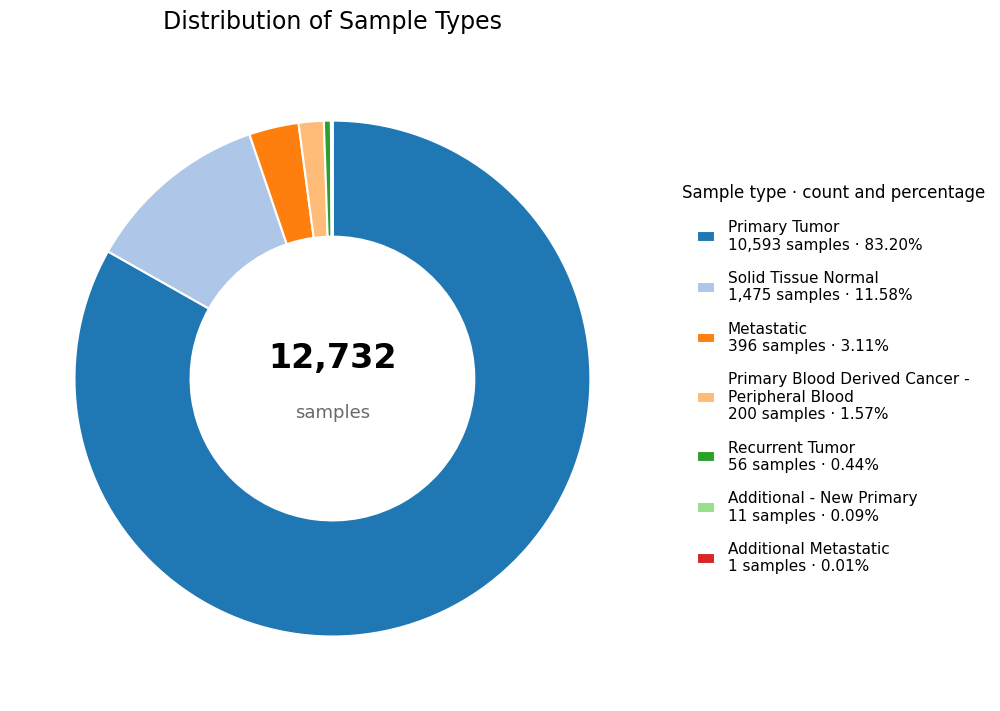

In [ ]:
# Distribución de tipos de muestra: etiquetas y porcentajes en una leyenda externa.
from textwrap import fill

sample_type_counts = labels["sample_type"].value_counts()
total_samples = sample_type_counts.sum()

fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
colors = plt.get_cmap("tab20").colors
wedges, _ = ax.pie(
    sample_type_counts,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 1.5},
)

# El centro muestra el total; la leyenda evita textos superpuestos en sectores pequeños.
ax.text(0, 0.08, f"{total_samples:,}", ha="center", va="center",
        fontsize=24, fontweight="bold")
ax.text(0, -0.13, "samples", ha="center", va="center", fontsize=13, color="dimgray")

legend_labels = [
    f"{fill(str(name), width=32)}\n{count:,} samples · {count / total_samples:.2%}"
    for name, count in sample_type_counts.items()
]
ax.legend(
    wedges, legend_labels,
    title="Sample type · count and percentage",
    loc="center left", bbox_to_anchor=(1.02, 0.5),
    fontsize=11, title_fontsize=12,
    frameon=False, labelspacing=1.2, handlelength=1.2,
)
ax.set_title("Distribution of Sample Types", fontsize=17, pad=20)
ax.set_aspect("equal")
plt.show()


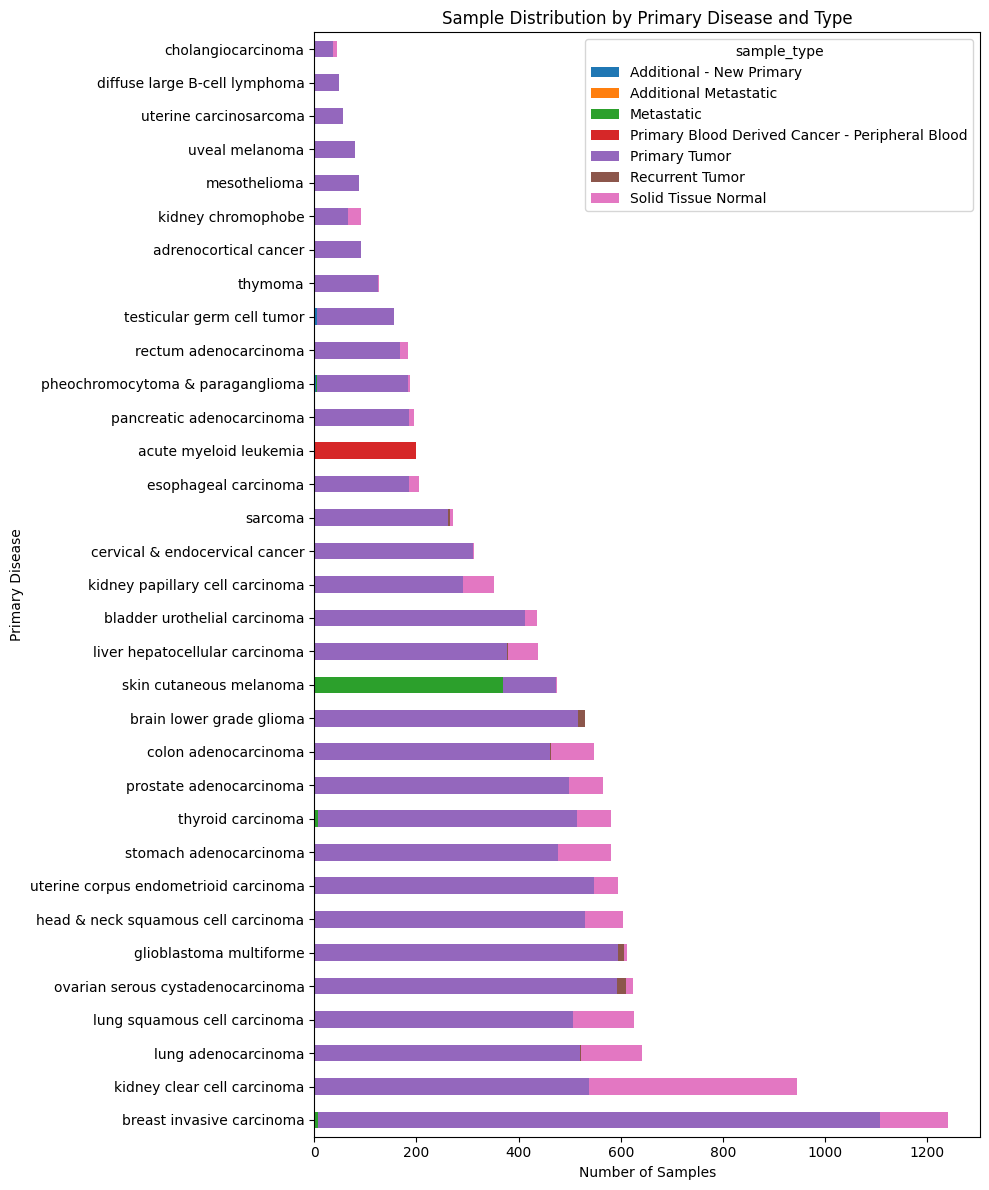

In [ ]:
# Barras apiladas: tipos de muestra por enfermedad primaria
df_plot = (
    labels
    .groupby(["primary_disease", "sample_type"])
    .size()
    .reset_index(name="n")
)
total_order = (
    df_plot.groupby("primary_disease")["n"]
    .sum()
    .sort_values(ascending=False)
    .index
)
pivot = df_plot.pivot_table(
    index="primary_disease", columns="sample_type", values="n", fill_value=0
)
pivot = pivot.loc[total_order]
pivot.plot(kind="barh", stacked=True, figsize=(10, 12))
plt.title("Sample Distribution by Primary Disease and Type")
plt.xlabel("Number of Samples")
plt.ylabel("Primary Disease")
plt.tight_layout()
plt.show()



## 2.4. Selección de un subconjunto para un análisis eficiente
Para reducir el costo computacional de esta fase exploratoria, trabajaremos con un subconjunto aleatorio de los datos. Es una forma práctica de probar rápidamente nuestro flujo de análisis.

Sin embargo, este método implica un equilibrio entre eficiencia y posible pérdida de información. Te invitamos a **experimentar** modificando las variables `n.genes` y `n.samples` que se indican a continuación para observar estos efectos.

**Consideraciones principales:**

- **Reducir el número de genes (`n.genes`):** acelera los cálculos, pero puede excluir genes clave que definen subtipos biológicos importantes y producir una interpretación incompleta.
- **Reducir el número de muestras (`n.samples`):** disminuye la potencia estadística y puede limitar la generalización a toda la cohorte, especialmente si se excluyen por azar subtipos poco frecuentes.

In [ ]:
rng = np.random.default_rng(123)

n_genes = 200
n_samples = 1000

gene_idx = rng.choice(df.shape[0], size=n_genes, replace=False)
sample_idx = rng.choice(df.shape[1], size=n_samples, replace=False)

df = df.iloc[gene_idx, sample_idx]

# Transponer: observaciones (muestras) en filas y variables (genes) en columnas
df = df.T

print(df.iloc[:4, :4])


gene             C4orf47   DPPA2  SLCO1B3  ZNF595
TCGA-67-3771-01   4.2661  5.1509   0.0000  9.7800
TCGA-V1-A8MU-01   2.6371  0.0000   1.7540  7.6187
TCGA-06-2567-01   5.8882  0.0000   0.0000  7.1047
TCGA-DD-A4NH-01   2.0814  0.0000   5.8198  7.1675


## 2.5. Alineación de las anotaciones con los datos de expresión
Para asegurar que las etiquetas clínicas correspondan a las muestras de la matriz de expresión, alinearemos `labels` con el subconjunto `df` mediante los identificadores de muestra (nombres de las filas).

In [ ]:
labels = labels.set_index("sample")
labels = labels.loc[df.index]

print(labels.shape, df.shape)
print(labels.head())

(1000, 3) (1000, 200)
                 sample_type_id    sample_type                 primary_disease
TCGA-67-3771-01             1.0  Primary Tumor             lung adenocarcinoma
TCGA-V1-A8MU-01             1.0  Primary Tumor         prostate adenocarcinoma
TCGA-06-2567-01             1.0  Primary Tumor         glioblastoma multiforme
TCGA-DD-A4NH-01             1.0  Primary Tumor  liver hepatocellular carcinoma
TCGA-FG-A60K-01             1.0  Primary Tumor        brain lower grade glioma


In [ ]:
labels

,sample_type_id,sample_type,primary_disease
TCGA-67-3771-01,1.0,Primary Tumor,lung adenocarcinoma
TCGA-V1-A8MU-01,1.0,Primary Tumor,prostate adenocarcinoma
TCGA-06-2567-01,1.0,Primary Tumor,glioblastoma multiforme
TCGA-DD-A4NH-01,1.0,Primary Tumor,liver hepatocellular carcinoma
TCGA-FG-A60K-01,1.0,Primary Tumor,brain lower grade glioma
...,...,...,...
TCGA-AO-A1KR-01,1.0,Primary Tumor,breast invasive carcinoma
TCGA-AK-3460-01,1.0,Primary Tumor,kidney clear cell carcinoma
TCGA-OR-A5JT-01,1.0,Primary Tumor,adrenocortical cancer
TCGA-BP-4760-01,1.0,Primary Tumor,kidney clear cell carcinoma


## 2.6. Resumen del conjunto de datos

Revisemos cuántas muestras hay de cada tipo de cáncer en el subconjunto final. **Puedes modificar el código para añadir gráficas similares a las de la sección 2.3.**

                          primary_disease  n_obs
0               breast invasive carcinoma    125
1             kidney clear cell carcinoma     71
2                       thyroid carcinoma     61
3                     lung adenocarcinoma     58
4            lung squamous cell carcinoma     57
5     head & neck squamous cell carcinoma     52
6            bladder urothelial carcinoma     48
7                 prostate adenocarcinoma     48
8          liver hepatocellular carcinoma     43
9                brain lower grade glioma     42
10                 stomach adenocarcinoma     39
11                skin cutaneous melanoma     37
12                   colon adenocarcinoma     32
13         cervical & endocervical cancer     30
14                                sarcoma     29
15      ovarian serous cystadenocarcinoma     26
16        kidney papillary cell carcinoma     23
17                   esophageal carcinoma     22
18              pancreatic adenocarcinoma     20
19                 a

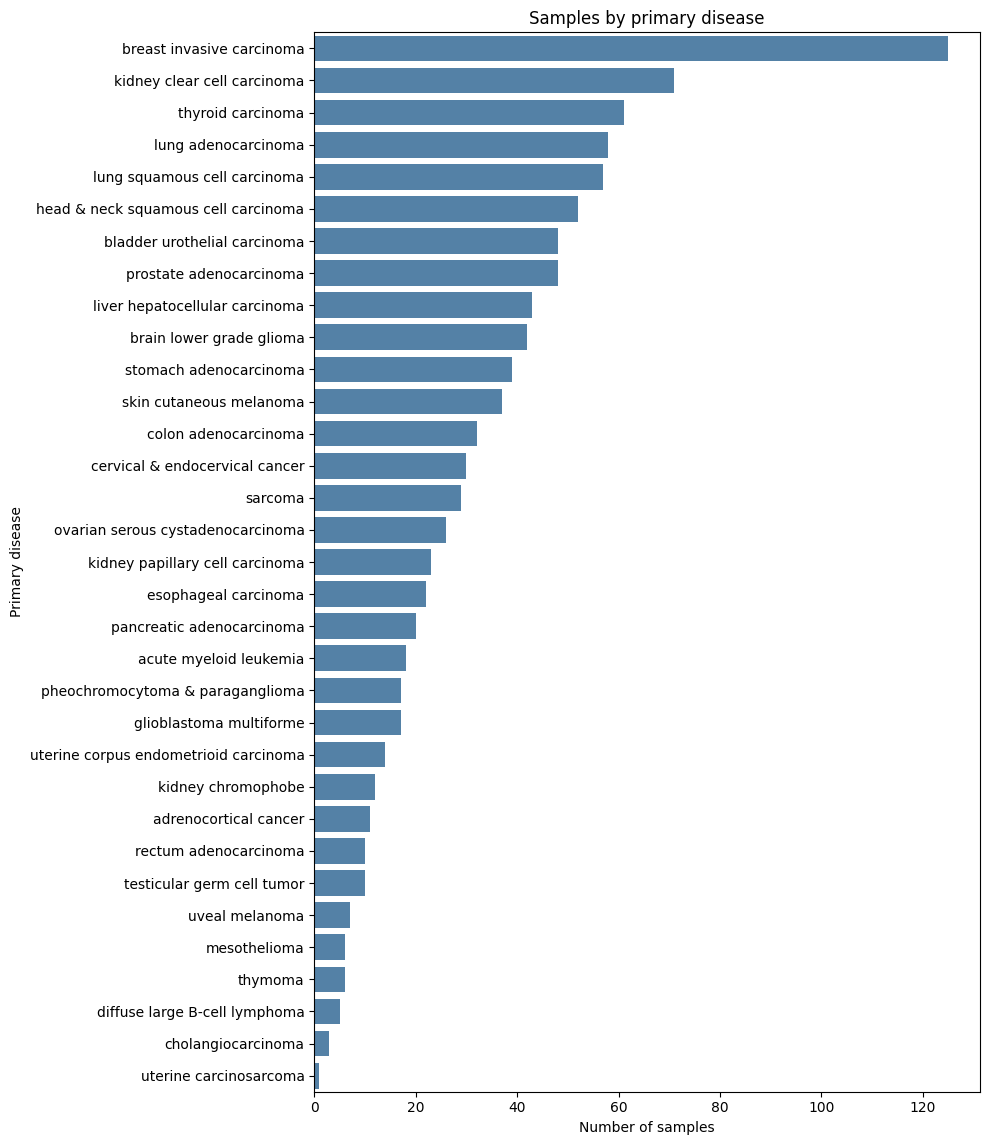

In [ ]:
summary = (
    labels["primary_disease"]
    .value_counts()
    .rename_axis("primary_disease")
    .reset_index(name="n_obs")
)
print(summary)

# Number of samples by primary disease in the subset
fig, ax = plt.subplots(figsize=(10, max(5, 0.35 * len(summary))))
sns.barplot(data=summary, x="n_obs", y="primary_disease", color="steelblue", ax=ax)
ax.set(title="Samples by primary disease", xlabel="Number of samples", ylabel="Primary disease")
fig.tight_layout()
plt.show()


## 2.7. Reducción de dimensionalidad

Los datos de alta dimensionalidad, en los que el número de variables (genes) supera ampliamente al de observaciones (muestras), son difíciles de interpretar directamente. La **reducción de dimensionalidad** transforma estos datos en un espacio de menor dimensión para capturar sus patrones y relaciones principales, facilitando la visualización y el agrupamiento.

### 2.7.1. Análisis de componentes principales (PCA)
El análisis de componentes principales (PCA) es una técnica lineal de reducción de dimensionalidad. Transforma los datos en nuevas variables no correlacionadas, llamadas **componentes principales (PC)**, ordenadas según la varianza que explican. La primera componente (PC1) explica la mayor varianza; PC2, la segunda mayor, y así sucesivamente ([Jolliffe, 2002](https://link.springer.com/book/10.1007/b98835)). Graficar las primeras componentes permite visualizar las principales fuentes de variación.

El agrupamiento de datos moleculares identifica relaciones que no son evidentes mediante la patología convencional. Puede estratificar pacientes **dentro de un mismo tipo de cáncer** en subgrupos biológicos; por ejemplo, los subtipos intrínsecos del cáncer de mama orientan decisiones terapéuticas ([Perou et al., 2000](https://doi.org/10.1038/35021093)). También puede revelar similitudes **entre distintos tipos de tumor** debidas a mecanismos moleculares compartidos, independientemente del tejido de origen ([Hoadley et al., 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X)). Esta perspectiva pancáncer sustenta los «ensayos de canasta», en los que se administran terapias dirigidas según marcadores moleculares, como las fusiones de `NTRK`, en lugar de la localización anatómica del cáncer ([Drilon et al., 2018](https://doi.org/10.1056/NEJMoa1714448)).

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza PCA sobre la muestra de datos y agrega visualizaciones en 2D para identificar la enfermedad principal (primary disease) y el tipo de muestra (sample type). Contesta las siguientes preguntas:
> - ¿Cuál es el patrón más destacado en la gráfica PC1 frente a PC2?  
> - ¿Las muestras se agrupan, en general, según `primary_disease` o `sample type`?
> - ¿Puedes encontrar distintos tipos de cáncer que se agrupen cerca unos de otros?
> - Según la distribución observada, ¿qué factor biológico principal crees que representan PC1 y PC2?
>
> *⏱️ Tiempo estimado: 15 minutos*

### 2.7.2. Similitud molecular entre tipos de cáncer
Al calcular el perfil promedio de expresión génica de cada enfermedad se obtiene una «firma molecular» representativa. Después se correlacionan estas firmas para construir una matriz de similitud, que se visualiza mediante un mapa de calor con agrupamiento. Esta visualización revela una taxonomía molecular de los cánceres: permite identificar familias de tumores con características transcriptómicas compartidas, independientemente de su origen anatómico, y descubrir relaciones potencialmente inesperadas entre enfermedades.

In [ ]:
# Combine expression data with disease labels
df_with_labels = df.copy()
df_with_labels.insert(0, "disease", labels["primary_disease"].values)

# Calculate the average gene expression profile for each cancer type
cancer_centroids = (
    df_with_labels
    .groupby("disease")
    .mean(numeric_only=True)
)

# Calculate Pearson correlation between cancer types
# Rows are cancer types, columns are genes, so transpose before corr()
cancer_correlation_matrix = cancer_centroids.T.corr(method="pearson")

# Distance matrix equivalent to as.dist(1 - cancer_correlation_matrix)
cancer_distance_matrix = 1 - cancer_correlation_matrix


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza clustering jerárquico sobre la matriz de distancias. Incluye un heatmap para visualizar las similaridades (distancia o correlación, pero elige un rango adecuado de valores) y discute los resultados.
> ¿Encuentras patrones interesantes?  

> *⏱️ Tiempo estimado: 15 minutos*

### 2.7.3. Reducción de dimensión no-lineal con t-SNE

[t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) es un método no lineal para visualizar datos de alta dimensionalidad. A diferencia de PCA, que conserva la varianza global, t-SNE busca preservar la estructura local de vecindad, lo que facilita identificar grupos distintos.

Es un algoritmo probabilístico que modela las similitudes entre pares de muestras en un espacio de baja dimensión, a diferencia de la transformación lineal y determinista de PCA. Por ello, su interpretación también cambia: la agrupación de puntos es significativa, pero el tamaño relativo de los grupos y las distancias **entre** ellos generalmente no lo son. Para una guía detallada, consulta [«Cómo utilizar t-SNE eficazmente»](https://distill.pub/2016/misread-tsne/).

En análisis biológico, t-SNE se utiliza para identificar o confirmar subgrupos discretos dentro de una población más amplia según sus perfiles moleculares. Suele complementar a PCA: mientras PCA muestra estructuras generales, t-SNE puede descomponer esos grupos en subgrupos más sutiles y ayudar a formular hipótesis sobre subtipos moleculares poco frecuentes o aún no clasificados.

Puedes modificar los hiperparámetros `perplexity` y `max_iter` para evaluar la sensibilidad del algoritmo y la estabilidad de la visualización.

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza tSNE sobre los datos reducidos.

> - ¿Cómo se compara t-SNE con PCA en su capacidad para separar los tipos de cáncer? ¿Produce t-SNE grupos más diferenciados y compactos para cada `primary disease` y `sample type`?
> - ¿Algunos tipos de cáncer aparecen de forma consistente en la misma región, lo que sugiere similitudes locales en la estructura de los datos?

> *⏱️ Tiempo estimado: 15 minutos*

### 2.7.4. Clustering sobre las coordenadas t-SNE

**Ejercicio**: realiza clústering con k-means y DBSCAN en ésta representación

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza clustering con k-means y DBSCAN en ésta representación. ¿Los grupos que arrojan los métodos tienen relación con los tipos de muestra o la enfermedad primaria?

> *⏱️ Tiempo estimado: 10 minutos*

### 2.8. Otras estrategias de visualización

Cuando hay muchas categorías, las gráficas convencionales pueden resultar saturadas. A continuación presentamos dos estrategias para mejorar su visualización.

#### 2.8.1. Mejorar la disposición de la leyenda

Si hay muchas etiquetas, colocar la leyenda debajo de la gráfica y distribuirla en varias filas permite disponer de más espacio para los datos.

In [ ]:
fig = px.scatter(
    tsne_df, x="tSNE1", y="tSNE2", color="disease",
    title="t-SNE with Optimized Legend"
)
fig.update_layout(
    legend=dict(
        orientation="h", yanchor="top", y=-0.2,
        xanchor="left", x=0, font=dict(size=8)
    )
)
fig.show()


### 2.9. Análisis centrado en tipos de cáncer seleccionados
Para facilitar la interpretación, podemos aplicar PCA a un subconjunto más pequeño de tipos de cáncer. Esto puede revelar patrones específicos de subtipos que quedan ocultos en el análisis pancáncer.

#### 2.9.1. Subconjunto aleatorio de tipos de cáncer
Las etiquetas se pueden seleccionar aleatoriamente; su cantidad se modifica con la variable `n.labels`.

In [ ]:
rng2 = np.random.default_rng(123)
diseases = labels["primary_disease"].unique()
n_labels = 10
labels_to_keep = rng2.choice(diseases, size=n_labels, replace=False)

samples_to_keep = labels[labels["primary_disease"].isin(labels_to_keep)].index
df_sub = df.loc[samples_to_keep]

# Conservar solo columnas con varianza no nula para evitar errores al escalar
df_sub = df_sub.loc[:, df_sub.var(axis=0) != 0]



> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza todos los análisis que hiciste en la Sección 2.7, (reducción de dimensión y clústering). ¿Qué diferencias hay respecto a lo anterior? ¿Qué otro criterio se te ocurre para seleccionar tipos de cáncer para su estudio?

> *⏱️ Tiempo estimado: 15 minutos*

## 2.10. Análisis basados en distancias

Calculamos matrices de disimilitud y las utilizamos para agrupamiento y ordenación.

### 2.10.1. Cálculo de matrices de distancia

Calcularemos distintas métricas para explorar las relaciones entre muestras.

- **Euclidiana:** distancia convencional en el espacio geométrico; sensible a la magnitud.
- **Bray-Curtis:** basada en datos de abundancia; sensible a la composición.
- **Jaccard:** basada en presencia/ausencia; mide diferencias en la composición de las comunidades.

**Disimilitud de Bray-Curtis**

La disimilitud de Bray-Curtis cuantifica las diferencias de composición entre dos sitios o comunidades. Se utiliza con frecuencia en ecología para comparar abundancias de especies o características entre muestras. Su fórmula es:

$$BC = \frac{\sum |x_i - y_i|}{\sum (x_i + y_i)}$$

Donde:

- $x_i$ y $y_i$ son las abundancias (o conteos) de la característica $i$ en las muestras X e Y, respectivamente.
- El numerador suma las diferencias absolutas entre las abundancias de cada característica.
- El denominador suma las abundancias totales de ambas muestras.

Bray-Curtis varía entre 0 (muestras idénticas) y 1 (sin características compartidas, o con abundancias muy diferentes en las características comunes). Es sensible tanto a la presencia/ausencia como a la abundancia de las características.

*Ejemplo:*

Consideremos dos comunidades (muestra X y muestra Y) con los conteos de cuatro especies (A, B, C y D):

- **Muestra X:** (A=10, B=5, C=0, D=8)
- **Muestra Y:** (A=8, B=0, C=12, D=8)

\begin{array}{|l|c|c|c|c|c|}
\hline
\textbf{Especie} & \textbf{A} & \textbf{B} & \textbf{C} & \textbf{D} & \textbf{Total}\\
\hline
\textbf{Muestra X ($x_i$)} & 10 & 5 & 0 & 8 & 23 \\
\textbf{Muestra Y ($y_i$)} & 8 & 0 & 12 & 8 & 28 \\
\textbf{$|x_i - y_i|$} & $|10-8|=2$ & $|5-0|=5$ & $|0-12|=12$ & $|8-8|=0$ & $\sum |x_i - y_i| = 19$ \\
\textbf{$(x_i + y_i)$} & $10+8=18$ & $5+0=5$ & $0+12=12$ & $8+8=16$ & $\sum (x_i + y_i) = 51$ \\
\hline
\end{array}

BC = $\frac{19}{51}$ $\approx$ 0.373

Este valor refleja una disimilitud moderada basada en las abundancias de las especies. Considera tanto las especies compartidas como las diferencias en sus cantidades.

**Disimilitud de Jaccard**

La disimilitud de Jaccard mide las diferencias entre conjuntos finitos. Se utiliza habitualmente con datos binarios de presencia/ausencia y se centra en los elementos compartidos o exclusivos de dos conjuntos. Su fórmula es:

$$J = 1 - \frac{|A \cap B|}{|A \cup B|}$$

Donde:

- $|A \cap B|$ es el número de características comunes a los conjuntos A y B (intersección).
- $|A \cup B|$ es el número total de características distintas presentes en A o B (unión).

La disimilitud de Jaccard varía entre 0 (conjuntos idénticos, con todas las características compartidas) y 1 (conjuntos disjuntos, sin características compartidas).

*Ejemplo:*

Consideremos dos comunidades con presencia (1) o ausencia (0) de cuatro especies:

- **Comunidad 1 (vector de presencia $P_1$):** [1, 1, 0, 1] (están presentes las especies 1, 2 y 4).
- **Comunidad 2 (vector de presencia $P_2$):** [1, 0, 1, 1] (están presentes las especies 1, 3 y 4).

\begin{array}{|l|c|c|c|c|c|}
\hline
\textbf{Especie} & \textbf{1} & \textbf{2} & \textbf{3} & \textbf{4} \\
\hline
\textbf{Comunidad 1 ($P_1$)} & 1 & 1 & 0 & 1 \\
\textbf{Comunidad 2 ($P_2$)} & 1 & 0 & 1 & 1 \\
\textbf{Intersección ($P_1 \cap P_2$)} & 1 & 0 & 0 & 1 & $|\textbf{Intersección}| = 2$ \\
\textbf{Unión ($P_1 \cup P_2$)} & 1 & 1 & 1 & 1 & $|\textbf{Unión}| = 4$ \\
\hline
\end{array}

Índice de Jaccard ($J_{idx}$) = $\frac{|\text{Intersección}|}{|\text{Unión}|} = \frac{2}{4} = 0.5$

Disimilitud de Jaccard ($J$) = $1 - J_{idx} = 1 - 0.5 = 0.5$

Este valor expresa diferencias basadas únicamente en presencia o ausencia. Un valor mayor indica menos especies compartidas.

In [ ]:
dist_euc_c = pdist(df.values, metric="euclidean")
dist_bray_c = pdist(df.values, metric="braycurtis")
dist_jacc_c = pdist((df.values > 1).astype(float), metric="jaccard")

### 2.10.2. Agrupamiento jerárquico y mapa de calor

El agrupamiento jerárquico construye una estructura de árbol (dendrograma) a partir de la similitud entre muestras. Visualizamos el resultado junto con un mapa de calor de los datos de expresión.

> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Realiza clustering jerárquico sobre las distancias calculadas antes, mostrando también un heatmap de las distancias. ¿Qué patrones encuentras?

> *⏱️ Tiempo estimado: 15 minutos*

# 3. Análisis de proteómica

Repetiremos parte del análisis anterior con datos proteómicos para investigar si aparecen patrones similares entre muestras a nivel de proteínas.

## 3.1. Antecedentes: datos proteómicos de TCGA

Los datos de este estudio se generaron mediante la plataforma de micromatrices de proteínas de fase inversa (RPPA). Esta técnica de alto rendimiento basada en anticuerpos cuantifica la abundancia de proteínas totales y modificadas en lisados tumorales. Para el proyecto Pan-Cancer Atlas de TCGA, las muestras se analizaron en el MD Anderson Cancer Center. La plataforma midió aproximadamente entre 200 y 300 proteínas seleccionadas por su relevancia en vías de señalización del cáncer. Los datos originales pasaron por un control de calidad exhaustivo y se normalizaron para corregir variaciones en la carga de proteínas, produciendo los valores de normalización basada en réplicas (RBN) utilizados aquí ([Liu et al., 2013](https://pmc.ncbi.nlm.nih.gov/articles/PMC4213190/)). Este proceso permite comparar la abundancia de proteínas entre las miles de muestras de la cohorte ([Akbani et al., 2014](https://www.nature.com/articles/ncomms4887)).

## 3.2. Justificación del análisis proteómico

Aunque la transcriptómica ofrece una visión amplia de la expresión génica, la abundancia de ARNm suele ser un indicador imperfecto de la abundancia de proteínas y de la función celular. La correlación entre el ARNm y sus productos proteicos es relativamente modesta debido a mecanismos complejos de regulación postranscripcional, traduccional y postraduccional ([Vogel y Marcotte, 2012](ttps://www.nature.com/articles/nrg3185)). Las proteínas, y no los transcritos, son las principales moléculas funcionales que ejecutan procesos celulares, actúan como dianas terapéuticas y forman la maquinaria de la célula. Medir directamente el proteoma ofrece una visión más directa de las vías biológicas activas y del estado funcional del tumor, complementando la información del transcriptoma.

## 3.3. Concordancia esperada con la transcriptómica

No debemos esperar resultados de agrupamiento idénticos entre proteómica y transcriptómica. La correlación general entre niveles de ARNm y proteínas en grandes conjuntos de datos de cáncer suele ser moderada, con coeficientes de correlación de Pearson al cuadrado ($R^2$) frecuentemente entre 0.2 y 0.4 ([Zhang et al., 2014](https://www.nature.com/articles/nature13438)). Esta discordancia tiene significado biológico: refleja diferencias en las tasas de traducción y degradación de proteínas, que varían entre genes y muestras. Por tanto, aunque se conserven algunos patrones generales ligados al tejido de origen, el agrupamiento proteómico puede revelar subgrupos distintos, determinados por regulación postranscripcional y diferencias en la actividad de las vías de señalización que no se observan a nivel de ARN.


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Amplia la descripción dada antes entre transcriptómica y proteómica. ¿Qué diferencias hay entre una y otra? ¿Cómo se obtienen ambos tipos de datos?

> *⏱️ Tiempo estimado: 7 minutos*


## 3.4. Carga y preparación de datos

Cargamos los datos proteómicos y las mismas etiquetas clínicas, y los alineamos para garantizar la correspondencia entre muestras.

In [9]:
##proteomics_path = "Data/pan_cancer_proteomics.txt"
proteomics_path = "data/pan_cancer_proteomics.txt"
proteomics = pd.read_csv(proteomics_path, sep="\t", index_col=0)

# Transponer para tener muestras en las filas y proteínas en las columnas
df_proteomics = proteomics.T

# Volver a cargar todas las etiquetas para buscar correspondencias con todas las muestras
#labels_full = pd.read_csv("Data/labels.tsv", sep="\t", na_values="")
labels_full = pd.read_csv("data/labels.tsv", sep="\t", na_values="")

labels_full.columns.values[3] = "primary_disease"
labels_full = labels_full.set_index("sample")

# Encontrar las muestras comunes y alinear ambas matrices
common_samples = df_proteomics.index.intersection(labels_full.index)
df_proteomics = df_proteomics.loc[common_samples]
labels_proteomics = labels_full.loc[common_samples]

print(df_proteomics.shape)
print(labels_proteomics.shape)
df_proteomics

(3454, 131)
(3454, 3)


Sample,1433EPSILON,4EBP1,4EBP1PS65,4EBP1PT37T46,53BP1,ACCPS79,ACC1,AKT,AKTPS473,AKTPT308,...,XRCC1,YAP,YAPPS127,YB1,YB1PS102,JNKPT183Y185,PAI1,MTORPS2448,ASNS,EGFR
TCGA-27-1833-01,0.354159,-0.765668,-0.200527,0.536203,-0.831080,0.028515,-0.662501,0.184653,1.062793,-0.510832,...,-0.231142,0.354492,-0.682578,-0.584139,0.326244,0.293156,1.800741,-0.039113,-0.513292,1.643135
TCGA-A5-A0GI-01,0.250009,-0.374590,0.195072,-0.298304,1.006317,0.327914,-0.040188,-0.007285,2.599809,2.169297,...,-0.204339,-0.058810,0.469751,-0.136670,-0.012109,-0.083342,-0.606477,0.194955,0.013131,0.090169
TCGA-BP-4165-01,0.222598,-0.380307,0.264028,-0.543908,-1.920805,-1.027610,-1.897745,-0.099745,0.133892,0.071053,...,-0.054197,0.397443,0.462954,-1.199005,-0.235836,0.168086,-0.540144,-0.109511,-1.097720,0.489403
TCGA-EY-A1GF-01,-0.048706,0.108869,-0.195315,-0.462706,0.706779,0.197589,0.030334,0.020560,3.032617,2.328308,...,-0.011672,0.021926,0.391847,-0.194302,-0.080818,-0.162695,-0.786541,-0.169739,-0.177251,0.197568
TCGA-CZ-4863-01,0.152346,0.084013,0.502963,-0.188861,-0.364346,-0.638009,-1.151583,-0.063761,0.293035,-0.389747,...,-0.323296,0.292710,0.576496,-0.522901,0.076435,0.098300,-0.156868,-0.006106,-1.016233,0.631362
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-CN-4728-01,-0.035999,0.154903,-0.530181,-1.667369,-0.798627,-0.612192,-1.142845,-0.050514,-0.581228,0.077635,...,-0.020080,0.972278,0.244166,-0.354045,0.198059,0.835581,0.847519,0.194198,-0.833161,0.775326
TCGA-B5-A0JZ-01,0.078950,-0.481774,0.022419,-0.742721,1.002955,0.207907,0.214270,0.051118,2.065414,2.194598,...,0.083053,0.238749,0.524353,0.288916,-0.123260,-0.420778,-0.709096,-0.401134,-0.349594,0.195724
TCGA-CV-7091-01,-0.199311,0.951466,0.003105,0.160255,-1.217582,-0.282502,-0.296047,-0.037299,-1.246533,-0.979511,...,-0.415263,0.114555,-0.213228,-0.406002,0.045264,0.002247,0.950301,-0.379659,-0.000230,0.449081
TCGA-FI-A2EY-01,0.120568,-0.946360,-0.172938,-0.636034,0.241778,2.347894,2.536922,-0.142597,-1.121332,-0.565509,...,0.310209,0.294693,1.285490,-0.502757,0.253016,0.171777,0.060052,0.047219,0.003859,0.355927


In [10]:
# Quitamos valores cero o nulos de las proteínas en las muestras
prot_valid_mask = (df_proteomics.sum(axis=0) > 0) & df_proteomics.notna().all(axis=0)
df_prot_valid = df_proteomics.loc[:, prot_valid_mask]
print(df_prot_valid.shape)
df_prot_valid

(3454, 75)


Sample,1433EPSILON,AMPKALPHA,AMPKPT172,AR,BAK,BAX,BCL2,BCLXL,BETACATENIN,BID,...,SRCPY527,STAT3PY705,SYK,VEGFR2,YAP,YAPPS127,YB1PS102,JNKPT183Y185,PAI1,EGFR
TCGA-27-1833-01,0.354159,-0.236600,-0.058746,0.352822,-0.302200,0.405959,-0.055346,-0.278391,0.883113,-0.079596,...,0.883250,0.305632,-0.511644,-1.247885,0.354492,-0.682578,0.326244,0.293156,1.800741,1.643135
TCGA-A5-A0GI-01,0.250009,0.024459,0.135031,0.149671,0.658030,-0.122344,0.567020,0.070947,2.005289,-0.073315,...,-0.417339,-0.589507,0.789399,-0.637651,-0.058810,0.469751,-0.012109,-0.083342,-0.606477,0.090169
TCGA-BP-4165-01,0.222598,0.449752,-0.021036,0.023179,0.921252,0.168241,0.621428,0.096277,-0.516317,0.167590,...,0.494432,-0.216300,-0.441972,0.065001,0.397443,0.462954,-0.235836,0.168086,-0.540144,0.489403
TCGA-EY-A1GF-01,-0.048706,0.186070,0.373748,0.287519,0.238406,-0.320637,-0.469708,-0.161215,1.727686,-0.211434,...,-0.257743,-0.804210,0.804442,-0.325811,0.021926,0.391847,-0.080818,-0.162695,-0.786541,0.197568
TCGA-CZ-4863-01,0.152346,1.318535,-0.091074,0.260154,0.687886,0.365444,0.228135,-0.011433,0.367740,0.016772,...,0.568591,-0.100815,0.168835,-0.120151,0.292710,0.576496,0.076435,0.098300,-0.156868,0.631362
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-CN-4728-01,-0.035999,0.131666,0.338648,-0.276211,3.057635,0.545712,-0.076210,0.888566,0.200383,-0.075808,...,-0.857493,-0.627861,-0.571885,0.462170,0.972278,0.244166,0.198059,0.835581,0.847519,0.775326
TCGA-B5-A0JZ-01,0.078950,0.263534,-0.367229,0.015102,0.758748,0.092220,0.323737,0.367047,1.663602,-0.006453,...,-0.170399,-0.739480,0.311930,0.062290,0.238749,0.524353,-0.123260,-0.420778,-0.709096,0.195724
TCGA-CV-7091-01,-0.199311,-0.719726,-0.028268,-0.704709,-0.293800,-0.095956,-0.774201,-0.240514,0.972260,-0.247006,...,-0.506064,-0.124289,0.276504,1.069102,0.114555,-0.213228,0.045264,0.002247,0.950301,0.449081
TCGA-FI-A2EY-01,0.120568,0.881914,1.047903,-0.326762,0.299497,0.320135,-0.119097,0.021888,0.060680,0.567372,...,-0.652109,0.275107,-1.770814,-1.066345,0.294693,1.285490,0.253016,0.171777,0.060052,0.355927


## 3.5. Reducción de dimensionalidad y análisis de clusters en proteómica


> ### 📝 **Ejercicio Práctico**
>
> **Instrucciones:** Como en el caso de transcriptómica, realiza reducción de dimensión usando PCA y tSNE en los datos seleccionados de proteómica. Visualiza el resultado para buscar patrones interesantes. Comenta y discute tus hallazgos.

> Realiza clústering usando k-Means y DBSCAN en ambas representaciones y verifica si los clústers detectados corresponden con alguna de las etiquetas (primary disease o sample type).

> *⏱️ Tiempo estimado: 15 minutos*